<a href="https://colab.research.google.com/github/linguyn/crop-maturity-detection/blob/main/02_explore_labels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/crop-maturity-detection
!pwd

Mounted at /content/drive
/content/drive/MyDrive/crop-maturity-detection
/content/drive/MyDrive/crop-maturity-detection


In [2]:
import json
%cd laboro_tomato/annotations

# load trainset annotations
with open("train.json", "r") as f_train:
  train_data = json.load(f_train)

print(train_data.keys())
print(train_data["annotations"][0])
print(train_data["categories"])

# load testset annotations
with open("test.json", "r") as f_test:
  test_data = json.load(f_test)


/content/drive/MyDrive/crop-maturity-detection/laboro_tomato/annotations
dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])
{'segmentation': [[1616.8775999999998, 1374.8384, 1609.8264000000001, 1269.0496, 1609.8264000000001, 1177.4048, 1647.4224000000002, 1088.0896, 1692.0696, 1024.6496, 1753.1904, 989.4144, 1835.4336, 951.808, 1908.2856, 947.1072, 1988.1888000000001, 958.8384, 2044.5984, 970.6112, 2112.7392, 1001.1456000000001, 2192.6736, 1071.6576, 2253.7632, 1153.9008000000001, 2272.5768, 1231.4432, 2267.8656, 1320.7584, 2260.8144, 1405.3728, 2223.2184, 1485.2864000000002, 2169.1488, 1544.0256, 2077.5144, 1593.3632, 1948.2528, 1621.568, 1851.9071999999999, 1635.6704, 1734.3768, 1579.2608, 1647.4224000000002, 1464.1119999999999]], 'area': 362918.13442559936, 'iscrowd': 0, 'image_id': 0, 'bbox': [1609.8264000000001, 947.1072, 662.7503999999997, 688.5631999999999], 'category_id': 3, 'id': 0}
[{'id': 1, 'name': 'b_fully_ripened', 'supercategory': 'type'}, {'id': 2, '

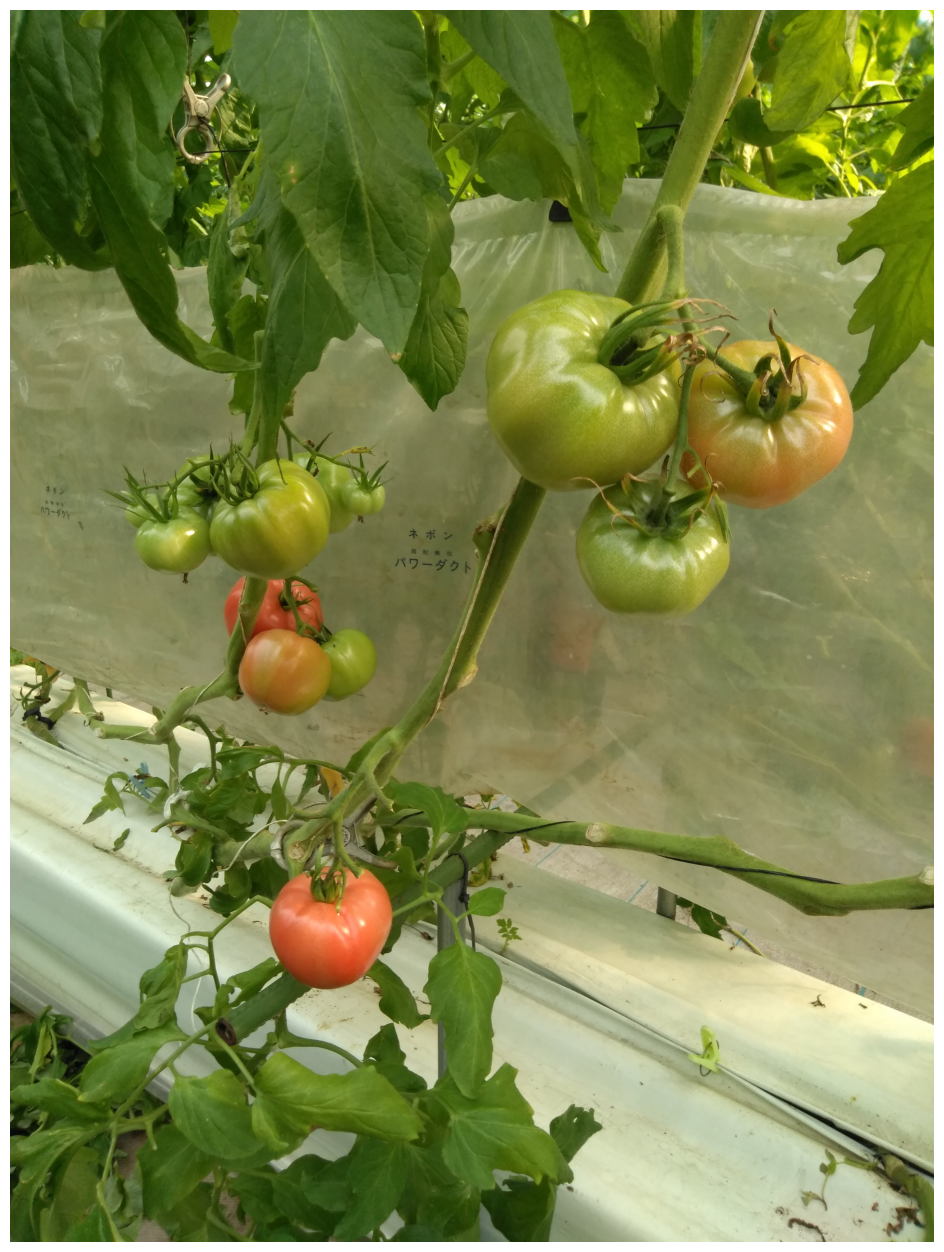

In [3]:
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

image_id = 0

file_name = train_data["images"][image_id]["file_name"]
image = cv2.imread(f"/content/drive/MyDrive/crop-maturity-detection/laboro_tomato/train/{file_name}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12,16))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()


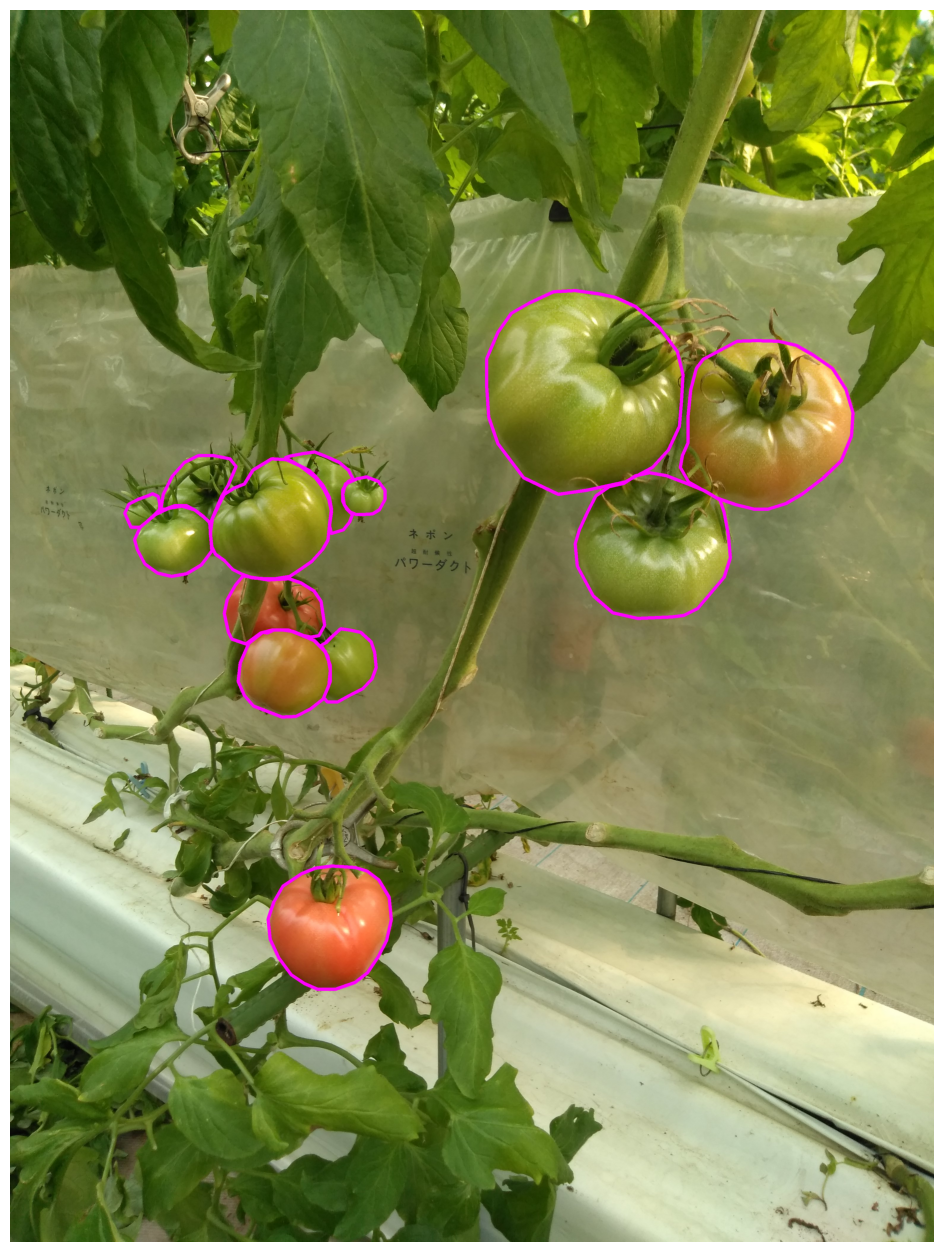

In [4]:
import numpy as np

# collect the outline points of every tomato in this image, for drawing
points = []

# get tomatoes' outlines
for ann in train_data["annotations"]:
  if ann["image_id"] == image_id:
    for seg in ann["segmentation"]:
      arr = np.array(seg).astype(np.int32)
      polygon = arr.reshape(-1, 2)
      points.append(polygon)



image_rgb_cp = image_rgb.copy()

# draw the outlines
cv2.polylines(image_rgb_cp, points, isClosed=True, color=(255, 0, 255), thickness=10)

plt.figure(figsize=(12,16))
plt.axis("off")
plt.imshow(image_rgb_cp)
plt.show()

In [5]:
# ID mapping from laboro category to our ripeness class
# 0 green, 1 half, 2 fully
my_ids = {
    1: 2,
    2: 1,
    3: 0,
    4: 2,
    5: 1,
    6: 0,
}

# counts tomatoes per ripeness class.
# input: list of COCO annotations
# output: [green, half, fully]
def count_tomatoes_per_class(annotations):
  ripeness_classes = [0, 0, 0]
  for ann in annotations:
    cls = my_ids[ann["category_id"]]
    ripeness_classes[cls] += 1
  return ripeness_classes

# store the total tomatoes of test set
test_total = count_tomatoes_per_class(test_data["annotations"])
# store the total tomatoes of train set
train_total = count_tomatoes_per_class(train_data["annotations"])
print(f"Total number of tomatoes in train set: {train_total}\n"
      f"Total number of tomatoes in test set: {test_total}")

Total number of tomatoes in train set: [5134, 1317, 1330]
Total number of tomatoes in test set: [1316, 339, 341]
